# Лабораторная работа № 2. Методы классификации и нейронные сети

**Цель:** изучить методы классификации Scikit-Learn, выполнить подбор гиперпараметров и обучить нейронную сеть TensorFlow с визуализацией процесса обучения в TensorBoard.

**Датасет:** Optical Recognition of Handwritten Digits (рукописные цифры), доступный через `sklearn.datasets.load_digits`.

**Характеристики:** 1797 изображений размером 8×8 пикселей, 64 числовых признака (яркость пикселей от 0 до 16).

**Задача:** бинарная классификация: чётная цифра (класс 0) или нечётная цифра (класс 1).

**Источник:** [Scikit-learn — Digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).


## 1. Настройка окружения


Python 3.10–3.12 рекомендуется для совместимости с TensorFlow. Установите зависимости **в терминале VS Code** командой:
'''powershell
python -m pip install numpy pandas matplotlib scikit-learn tensorflow tensorboard ipykernel



In [42]:
%pip install tensorflow
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import sys

print("Версия Python:", sys.version)
print("Путь к Python:", sys.executable)

import numpy
import tensorflow as tf

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("TensorFlow:", tf.__version__)

Версия Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Путь к Python: c:\Users\Никита Малов\AppData\Local\Programs\Python\Python311\python.exe
Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
NumPy: 2.4.6
TensorFlow: 2.21.0


In [44]:
from pathlib import Path
import os, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, validation_curve
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
SEED=42
np.random.seed(SEED); random.seed(SEED)
OUT=Path('results_lab2'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','axes.grid':True,'grid.alpha':0.2,'figure.dpi':110})
print('Рабочая папка:',Path.cwd())
print('Каталог результатов:',OUT)

Рабочая папка: c:\Users\Никита Малов\Downloads
Каталог результатов: results_lab2


**Пояснение.** Импортированы средства анализа данных, подготовки выборок, оценки классификаторов и построения графиков. Для воспроизводимости задано случайное зерно 42; изображения и таблицы сохраняются в папку `results_lab2`.

## 2. Загрузка и первичный анализ данных

Выбран **Optical Recognition of Handwritten Digits** (UCI, доступен в scikit-learn через `load_digits`). Набор содержит 1797 изображений рукописных цифр 8×8 пикселей, каждое изображение представлено 64 числовыми признаками интенсивности (0–16). Задача бинарной классификации: **чётная цифра (0)** или **нечётная цифра (1)**. Исходные цифры 0–9 сохраняются отдельно для визуализации. Это позволяет использовать все требуемые бинарные метрики, включая ROC-AUC, и сравнить четыре разновидности наивного Байеса на неотрицательных признаках.


Наблюдений: 1797 Признаков: 64
Пропусков: 0


,Пиксель 1–1,Пиксель 1–2,Пиксель 1–3,Пиксель 1–4,Пиксель 1–5,Пиксель 1–6,Пиксель 1–7,Пиксель 1–8,Пиксель 2–1,Пиксель 2–2,...,Пиксель 7–7,Пиксель 7–8,Пиксель 8–1,Пиксель 8–2,Пиксель 8–3,Пиксель 8–4,Пиксель 8–5,Пиксель 8–6,Пиксель 8–7,Пиксель 8–8
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
Пиксель 1–1,1797.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
Пиксель 1–2,1797.0,0.30,0.91,0.0,0.0,0.0,0.0,8.0
Пиксель 1–3,1797.0,5.20,4.75,0.0,1.0,4.0,9.0,16.0
Пиксель 1–4,1797.0,11.84,4.25,0.0,10.0,13.0,15.0,16.0
Пиксель 1–5,1797.0,11.85,4.29,0.0,10.0,13.0,15.0,16.0
...,...,...,...,...,...,...,...,...
Пиксель 8–4,1797.0,12.09,4.37,0.0,11.0,13.0,16.0,16.0
Пиксель 8–5,1797.0,11.81,4.93,0.0,10.0,14.0,16.0,16.0
Пиксель 8–6,1797.0,6.76,5.90,0.0,0.0,6.0,12.0,16.0
Пиксель 8–7,1797.0,2.07,4.09,0.0,0.0,0.0,2.0,16.0


,Класс,Количество
0,Чётная цифра (0),891
1,Нечётная цифра (1),906


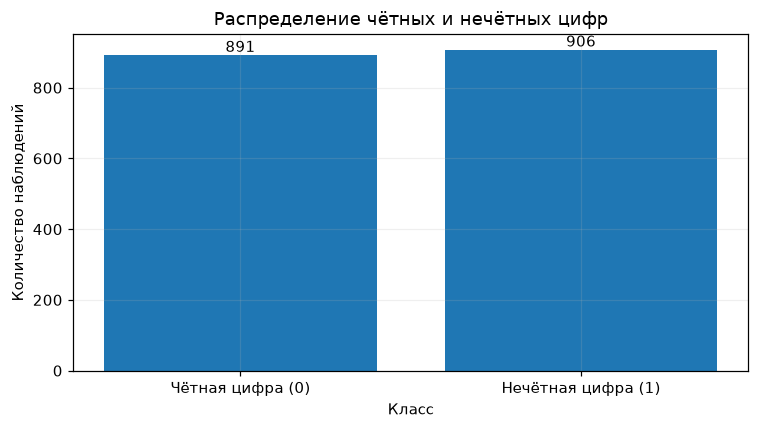

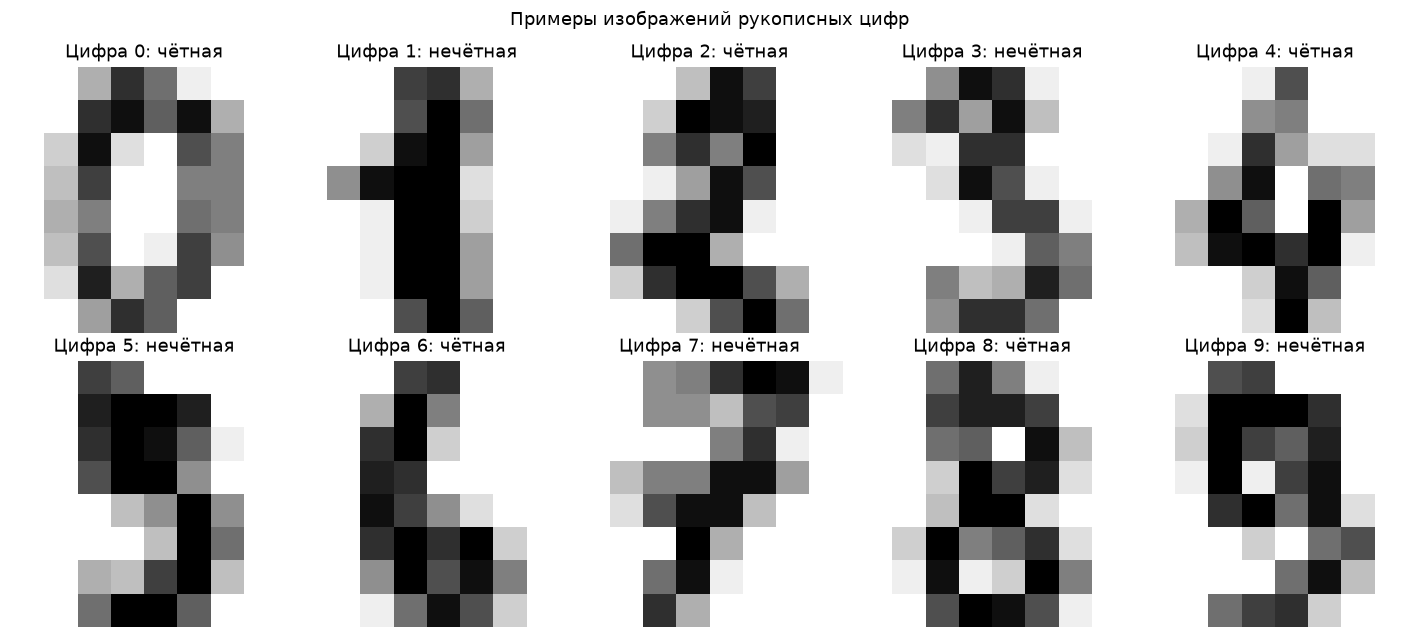

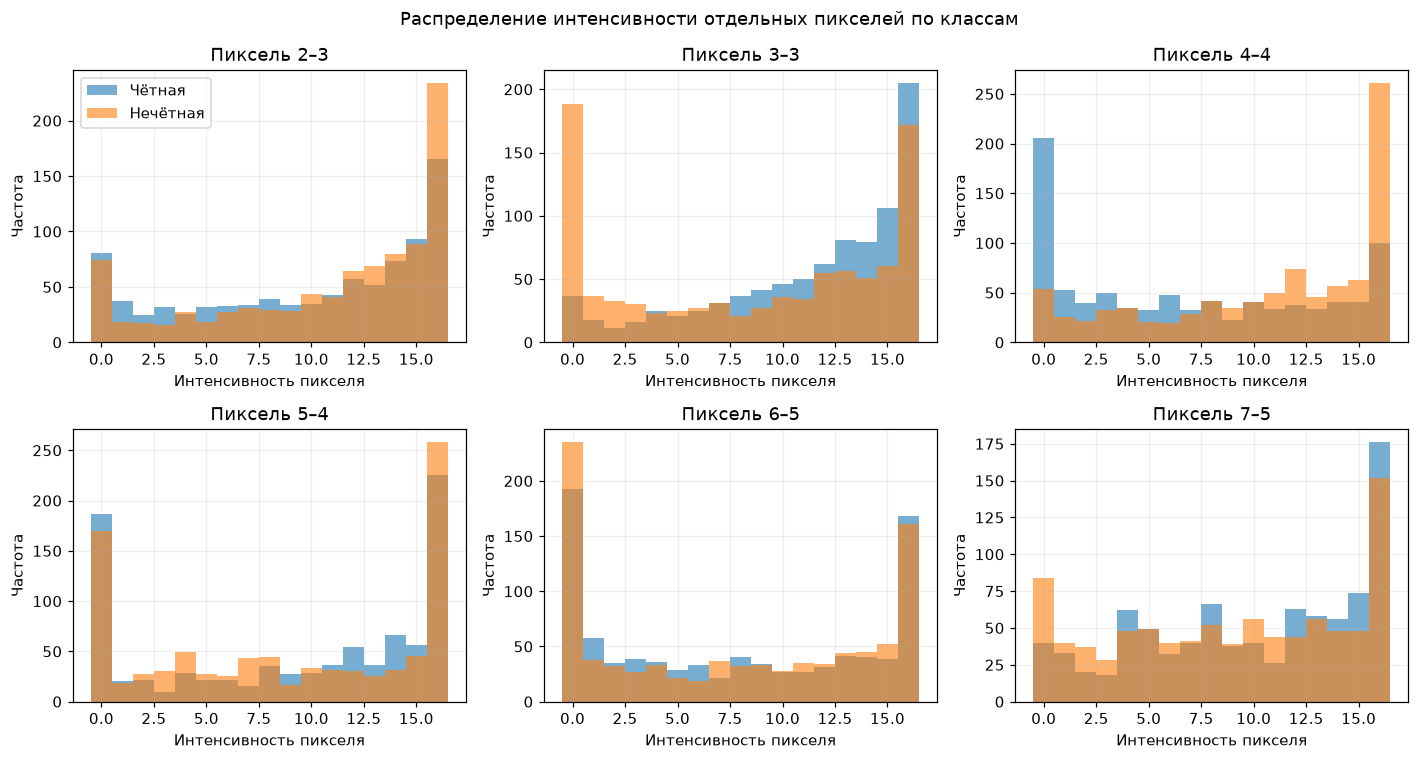

In [45]:
dataset = load_digits()
X = pd.DataFrame(dataset.data, columns=[f"Пиксель {i//8+1}–{i%8+1}" for i in range(64)])
digits_original = dataset.target
y = pd.Series((digits_original % 2 == 1).astype(int), name="Нечётная цифра")
print('Наблюдений:', len(X), 'Признаков:', X.shape[1])
print('Пропусков:', int(X.isna().sum().sum()))
display(X.head())
display(X.describe().T.round(2))
class_table = pd.DataFrame({'Класс': ['Чётная цифра (0)', 'Нечётная цифра (1)'],
                            'Количество': [(y==0).sum(), (y==1).sum()]})
display(class_table)
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(class_table['Класс'], class_table['Количество'])
ax.bar_label(bars)
ax.set(xlabel='Класс', ylabel='Количество наблюдений', title='Распределение чётных и нечётных цифр')
fig.tight_layout(); fig.savefig(OUT/'classes.png', dpi=180); plt.show()
fig, axes = plt.subplots(2, 5, figsize=(13,6))
for digit, ax in enumerate(axes.flat):
    idx = np.flatnonzero(digits_original == digit)[0]
    ax.imshow(dataset.images[idx], cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Цифра {digit}: ' + ('нечётная' if digit % 2 else 'чётная'))
    ax.axis('off')
fig.suptitle('Примеры изображений рукописных цифр')
fig.tight_layout(); fig.savefig(OUT/'digit_examples.png', dpi=180); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(13,7))
for ax, col in zip(axes.flat, X.columns[[10, 18, 27, 35, 44, 52]]):
    ax.hist(X.loc[y==0, col], bins=np.arange(-.5,17.5,1), alpha=.6, label='Чётная')
    ax.hist(X.loc[y==1, col], bins=np.arange(-.5,17.5,1), alpha=.6, label='Нечётная')
    ax.set(title=col, xlabel='Интенсивность пикселя', ylabel='Частота')
axes[0,0].legend()
fig.suptitle('Распределение интенсивности отдельных пикселей по классам')
fig.tight_layout(); fig.savefig(OUT/'features.png', dpi=180); plt.show()


**Анализ графиков.** Столбчатая диаграмма позволяет оценить баланс чётных и нечётных цифр. Изображения показывают различия в форме рукописных цифр, включая вариативность начертания. Гистограммы интенсивности выбранных пикселей демонстрируют, что отдельные области изображения по-разному заполняются для двух классов; при этом по одному пикселю невозможно надёжно классифицировать цифру. Поэтому модели обучаются по всем 64 признакам. Конкретные значения баланса и распределений отображаются при выполнении ноутбука.

## 3. Подготовка выборок

Пропущенных значений в исходном датасете нет. Все 64 признака числовые и неотрицательные. Используется стратифицированное разделение 80/20. Все преобразования данных и подбор параметров выполняются **внутри Pipeline и фолдов CV**, что предотвращает утечку информации из тестовой выборки.

In [46]:
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Обучающая выборка:',Xtr.shape,'Тестовая выборка:',Xte.shape)
print('Доля положительного класса: обучение',round(ytr.mean(),3),'тест',round(yte.mean(),3))
assert not Xtr.isna().any().any() and not Xte.isna().any().any()

Обучающая выборка: (1437, 64) Тестовая выборка: (360, 64)
Доля положительного класса: обучение 0.504 тест 0.506


**Пояснение.** Обучающая выборка используется для кросс-валидации и выбора гиперпараметров. Тестовая выборка остаётся нетронутой до итогового сравнения. Стратификация сохраняет долю нечётных случаев в обеих частях.

## 4. Обучение и подбор гиперпараметров

Рассматриваются **8 классификаторов** в рамках пяти семейств: четыре вида наивного Байеса, дерево решений, LDA, SVM и kNN. Для MultinomialNB/ComplementNB необходимы неотрицательные признаки — используется MinMaxScaler. Для BernoulliNB — бинаризация после MinMaxScaler. Для GaussianNB, LDA, SVM и kNN — стандартизация. Параметры подбираются по ROC-AUC с пятиблочной кросс-валидацией.

**Метрики:** Accuracy — доля верных прогнозов; Precision — точность положительных предсказаний; Recall — полнота положительного класса; F1 — гармоническое среднее Precision и Recall; ROC-AUC — способность ранжировать положительные объекты выше отрицательных.

In [47]:
specs={
 'Гауссовский Байес':(Pipeline([('scale',StandardScaler()),('model',GaussianNB())]),{'model__var_smoothing':[1e-12,1e-9,1e-6,1e-3]}),
 'Мультиномиальный Байес':(Pipeline([('scale',MinMaxScaler()),('model',MultinomialNB())]),{'model__alpha':[.01,.1,1,10]}),
 'Комплементарный Байес':(Pipeline([('scale',MinMaxScaler()),('model',ComplementNB())]),{'model__alpha':[.01,.1,1,10]}),
 'Бернуллиевский Байес':(Pipeline([('scale',MinMaxScaler()),('binary',Binarizer()),('model',BernoulliNB())]),{'binary__threshold':[.15,.3,.5,.7],'model__alpha':[.1,1]}),
 'Дерево решений':(Pipeline([('model',DecisionTreeClassifier(random_state=SEED))]),{'model__max_depth':[2,3,4,6,None],'model__min_samples_leaf':[1,3,7]}),
 'Линейный дискриминантный анализ':(Pipeline([('scale',StandardScaler()),('model',LinearDiscriminantAnalysis())]),{'model__solver':['svd','lsqr'],'model__shrinkage':[None]}),
 'Метод опорных векторов':(Pipeline([('scale',StandardScaler()),('model',SVC(probability=True,random_state=SEED))]),{'model__C':[.1,1,10,100],'model__kernel':['linear','rbf'],'model__gamma':['scale']}),
 'Метод ближайших соседей':(Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier())]),{'model__n_neighbors':[3,5,7,11,15],'model__weights':['uniform','distance']})
}
models={};rows=[];tuning=[]
for name,(pipeline,grid) in specs.items():
    search = GridSearchCV(
    estimator=pipeline,
    param_grid=grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1,
    refit=True,
    error_score='raise'
)
    search.fit(Xtr,ytr)
    model=search.best_estimator_;models[name]=model
    pred=model.predict(Xte);score=model.predict_proba(Xte)[:,1]
    rows.append({'Модель':name,'Accuracy':accuracy_score(yte,pred),'Precision':precision_score(yte,pred,zero_division=0),'Recall':recall_score(yte,pred,zero_division=0),'F1':f1_score(yte,pred,zero_division=0),'ROC-AUC':roc_auc_score(yte,score),'CV ROC-AUC':search.best_score_})
    tuning.append({'Модель':name,'Лучшие параметры':str(search.best_params_),'CV ROC-AUC':search.best_score_})
metrics=pd.DataFrame(rows).sort_values('ROC-AUC',ascending=False).reset_index(drop=True)
display(metrics.round(4));display(pd.DataFrame(tuning))
metrics.to_csv(OUT/'classification_metrics.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(tuning).to_csv(OUT/'best_parameters.csv',index=False,encoding='utf-8-sig')

c:\Users\Никита Малов\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Никита Малов\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Никита Малов\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Никита Малов\AppData\Local\Programs\Python\Python311\Li

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
0,Метод опорных векторов,0.9917,0.9945,0.9890,0.9917,0.9999,0.9993
1,Метод ближайших соседей,0.9833,0.9731,0.9945,0.9837,0.9997,0.9971
2,Дерево решений,0.9222,0.9278,0.9176,0.9227,0.9741,0.9515
3,Линейный дискриминантный анализ,0.8972,0.8919,0.9066,0.8992,0.9681,0.9689
4,Бернуллиевский Байес,0.8472,0.8128,0.9066,0.8571,0.9402,0.9230
5,Мультиномиальный Байес,0.8250,0.8083,0.8571,0.8320,0.9307,0.9191
6,Комплементарный Байес,0.8250,0.8115,0.8516,0.8311,0.9307,0.9191
7,Гауссовский Байес,0.6889,0.6215,0.9835,0.7617,0.9128,0.8975


,Модель,Лучшие параметры,CV ROC-AUC
0,Гауссовский Байес,{'model__var_smoothing': 0.001},0.897454
1,Мультиномиальный Байес,{'model__alpha': 10},0.919141
2,Комплементарный Байес,{'model__alpha': 10},0.919141
3,Бернуллиевский Байес,"{'binary__threshold': 0.3, 'model__alpha': 1}",0.922997
4,Дерево решений,"{'model__max_depth': None, 'model__min_samples...",0.951477
5,Линейный дискриминантный анализ,"{'model__shrinkage': None, 'model__solver': 's...",0.968878
6,Метод опорных векторов,"{'model__C': 10, 'model__gamma': 'scale', 'mod...",0.999292
7,Метод ближайших соседей,"{'model__n_neighbors': 15, 'model__weights': '...",0.997103


**Анализ метрик.** В таблице представлены результаты на независимой тестовой выборке и лучшая средняя ROC-AUC по кросс-валидации. При интерпретации особенно важен Recall для нечётного класса, поскольку он обозначен как положительный (1). Выбирать победителя исключительно по тестовому ROC-AUC нельзя: предпочтительнее учитывать CV ROC-AUC и устойчивость показателей. Значения и лучшие параметры определяются непосредственно при выполнении кода.

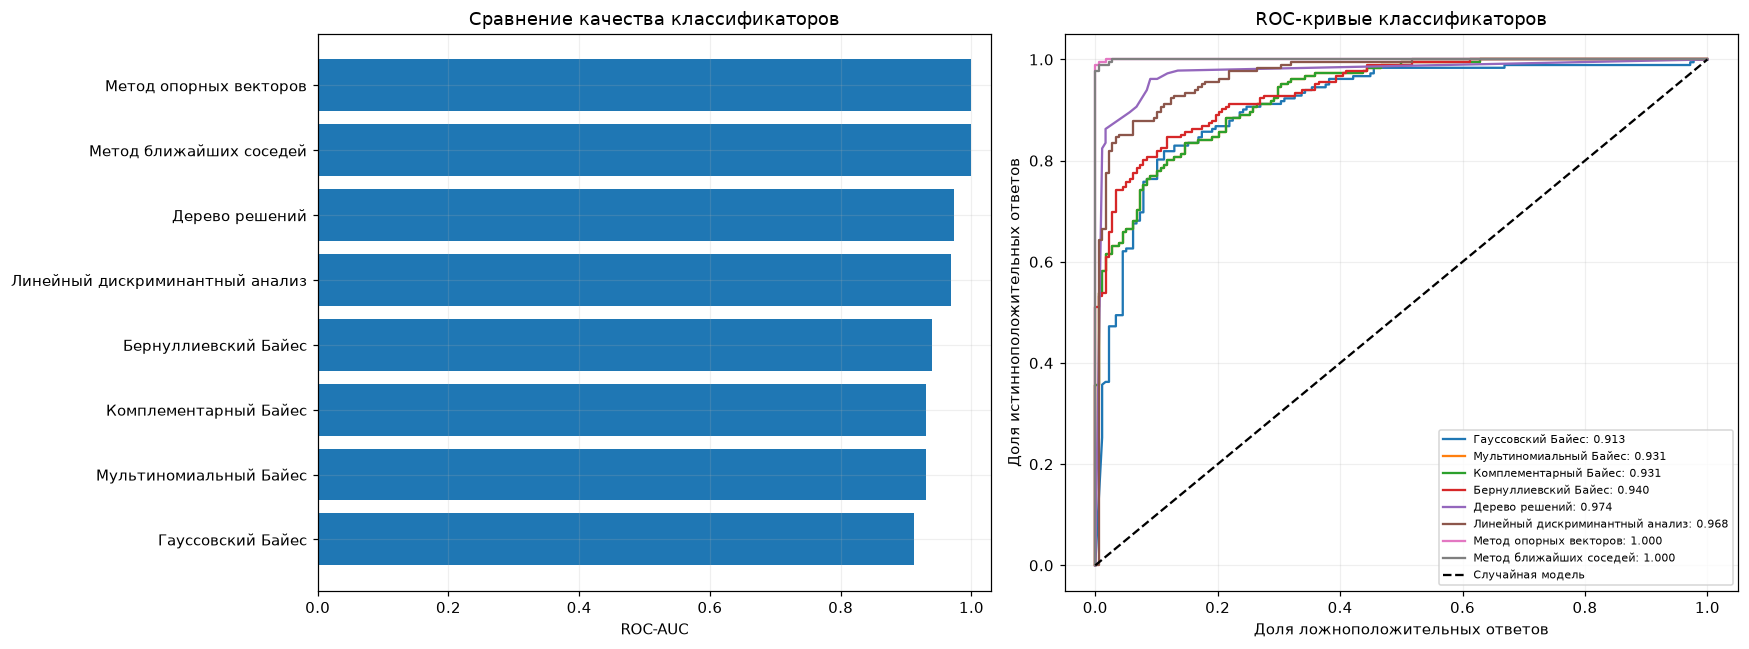

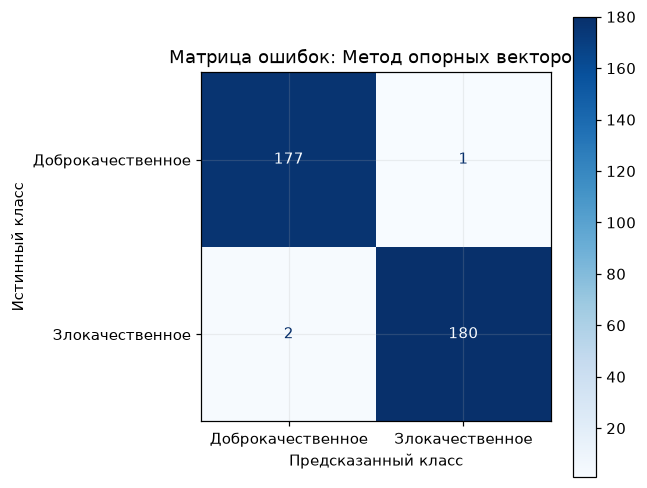

Лучшая модель по CV ROC-AUC: Метод опорных векторов


In [48]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
order=metrics.sort_values('ROC-AUC')
axes[0].barh(order['Модель'],order['ROC-AUC']);axes[0].set(xlim=(0,1.03),xlabel='ROC-AUC',title='Сравнение качества классификаторов')
for name,model in models.items():
    fpr,tpr,_=roc_curve(yte,model.predict_proba(Xte)[:,1]);auc=roc_auc_score(yte,model.predict_proba(Xte)[:,1]);axes[1].plot(fpr,tpr,label=f'{name}: {auc:.3f}',lw=1.5)
axes[1].plot([0,1],[0,1],'k--',label='Случайная модель');axes[1].set(xlabel='Доля ложноположительных ответов',ylabel='Доля истинноположительных ответов',title='ROC-кривые классификаторов');axes[1].legend(fontsize=7,loc='lower right')
fig.tight_layout();fig.savefig(OUT/'comparison_roc.png',dpi=180,bbox_inches='tight');plt.show()
best_name=pd.DataFrame(tuning).sort_values('CV ROC-AUC',ascending=False).iloc[0]['Модель'];best_model=models[best_name]
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay.from_predictions(yte,best_model.predict(Xte),display_labels=['Доброкачественное','Злокачественное'],cmap='Blues',ax=ax);ax.set(xlabel='Предсказанный класс',ylabel='Истинный класс',title='Матрица ошибок: '+best_name);fig.tight_layout();fig.savefig(OUT/'confusion.png',dpi=180);plt.show()
print('Лучшая модель по CV ROC-AUC:',best_name)

**Анализ графиков.** Левый график сравнивает ROC-AUC моделей: чем выше столбец, тем лучше разделяются классы. Справа ROC-кривые показывают компромисс между чувствительностью и долей ложных срабатываний; идеальная кривая стремится к левому верхнему углу. Матрица ошибок выбранной по CV модели позволяет отдельно оценить ложноположительные и ложноотрицательные прогнозы. В медицинском контексте ложноотрицательные случаи требуют особого внимания. Результаты носят учебный характер.

## 5. Исследование влияния гиперпараметров

Ниже исследуется зависимость качества SVM от `C`, kNN от числа соседей, дерева от максимальной глубины и GaussianNB от сглаживания дисперсии. Каждая точка — средняя ROC-AUC на пяти фолдах; закрашенная область отражает ±1 стандартное отклонение.

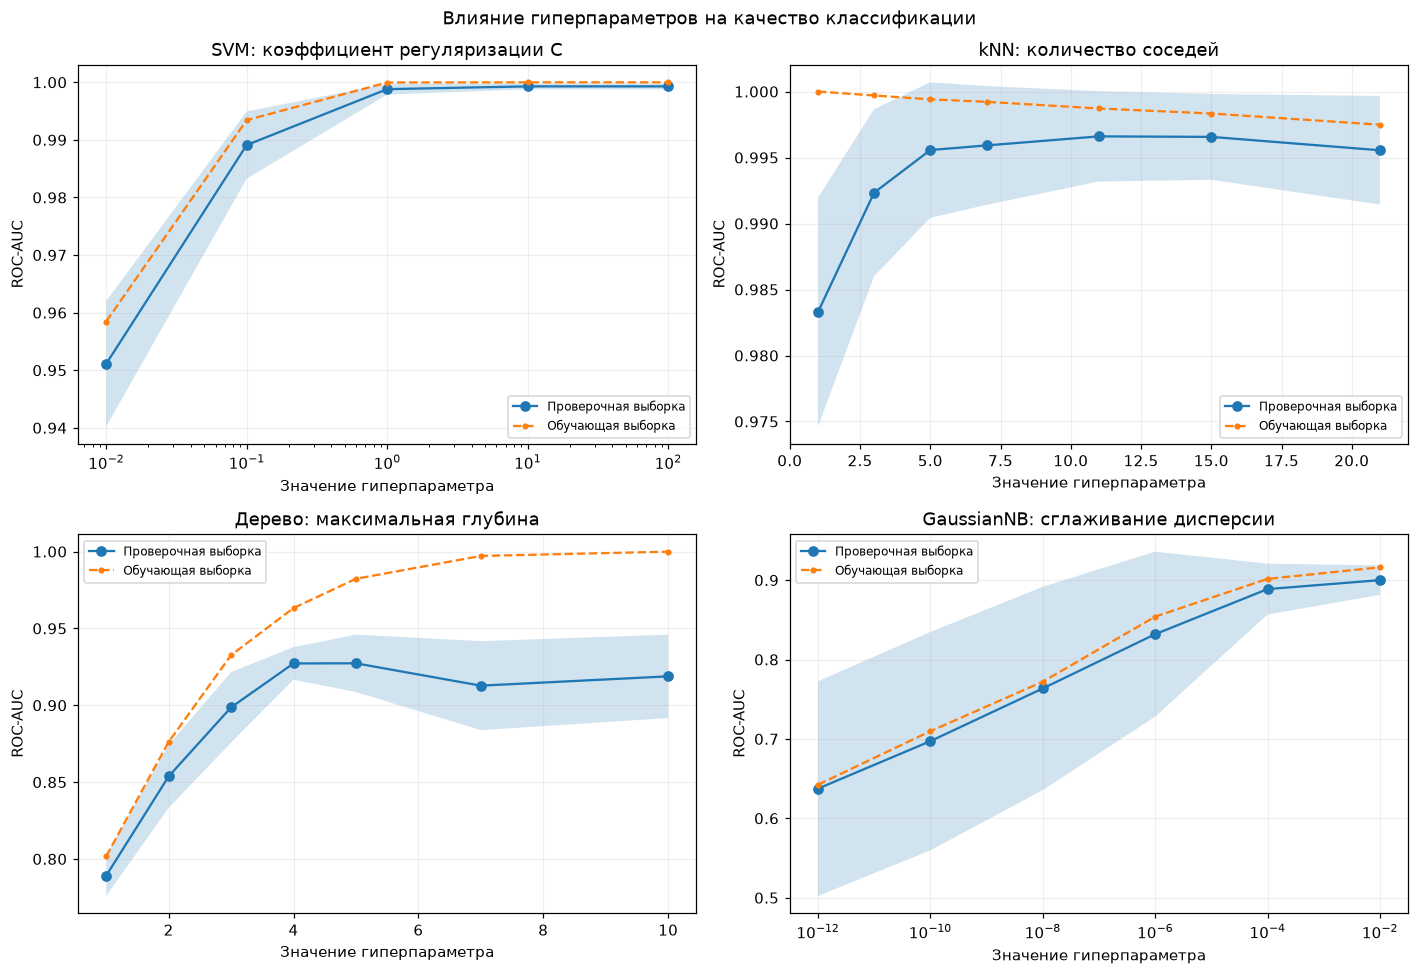

In [49]:
studies=[
 ('SVM: коэффициент регуляризации C',Pipeline([('scale',StandardScaler()),('model',SVC(kernel='rbf'))]),'model__C',[.01,.1,1,10,100],True),
 ('kNN: количество соседей',Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier())]),'model__n_neighbors',[1,3,5,7,11,15,21],False),
 ('Дерево: максимальная глубина',DecisionTreeClassifier(random_state=SEED),'max_depth',[1,2,3,4,5,7,10],False),
 ('GaussianNB: сглаживание дисперсии',Pipeline([('scale',StandardScaler()),('model',GaussianNB())]),'model__var_smoothing',[1e-12,1e-10,1e-8,1e-6,1e-4,1e-2],True)
]
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,(title,est,param,values,logscale) in zip(axes.flat,studies):
    tr,va=validation_curve(est,Xtr,ytr,param_name=param,param_range=values,cv=cv,scoring='roc_auc',n_jobs=1)
    a=np.asarray(values,dtype=float);mu=va.mean(axis=1);sd=va.std(axis=1)
    ax.plot(a,mu,marker='o',label='Проверочная выборка');ax.fill_between(a,mu-sd,mu+sd,alpha=.2)
    ax.plot(a,tr.mean(axis=1),marker='.',linestyle='--',label='Обучающая выборка')
    if logscale:ax.set_xscale('log')
    ax.set(title=title,xlabel='Значение гиперпараметра',ylabel='ROC-AUC');ax.legend(fontsize=8)
fig.suptitle('Влияние гиперпараметров на качество классификации');fig.tight_layout();fig.savefig(OUT/'hyperparameters.png',dpi=180);plt.show()

**Анализ графиков гиперпараметров.** При слишком малом `C` SVM может недообучаться; при большом `C` увеличивается риск подгонки к обучающей выборке. У kNN малое число соседей повышает чувствительность к шуму, а чрезмерно большое — сглаживает границу классов. У дерева большая глубина может давать переобучение: качество на обучении растёт, а на проверке перестаёт улучшаться. Для GaussianNB сглаживание стабилизирует оценку дисперсий; слишком большое значение может ухудшать качество. Конкретные оптимумы определяются по максимуму проверочной кривой, а не по обучающей.

## 6. Нейронная сеть TensorFlow и TensorBoard

Для нейронной сети используются только стандартизированные признаки. Внутри обучающей части выделяется отдельная валидационная выборка; тестовые данные не участвуют в выборе архитектуры. Исследуются 3 конфигурации (число нейронов, dropout, скорость обучения). Применяется ранняя остановка и TensorBoard. **TensorFlow должен быть установлен в выбранном ядре**.

In [50]:
%pip install --upgrade tensorboard

     ---------------------------------------- 5.5/5.5 MB 2.8 MB/s eta 0:00:00
     -------------------------------------- 116.8/116.8 kB 6.7 MB/s eta 0:00:00
     -------------------------------------- 228.7/228.7 kB 2.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Версия TensorFlow:", tf.__version__)

tf.keras.utils.set_random_seed(SEED)


Xnn_tr, Xnn_val, ynn_tr, ynn_val = train_test_split(
    Xtr,
    ytr,
    test_size=0.2,
    stratify=ytr,
    random_state=SEED
)


scaler_nn = StandardScaler().fit(Xnn_tr)

a_tr = scaler_nn.transform(Xnn_tr).astype("float32")
a_val = scaler_nn.transform(Xnn_val).astype("float32")
a_te = scaler_nn.transform(Xte).astype("float32")


configs_nn = [
    {
        "Название": "Малая сеть",
        "Нейроны": 16,
        "Dropout": 0.0,
        "Скорость": 0.001
    },
    {
        "Название": "Средняя сеть",
        "Нейроны": 32,
        "Dropout": 0.2,
        "Скорость": 0.001
    },
    {
        "Название": "Большая сеть",
        "Нейроны": 64,
        "Dropout": 0.35,
        "Скорость": 0.0005
    }
]


def make_nn(c):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(Xtr.shape[1],)),
        tf.keras.layers.Dense(
            c["Нейроны"],
            activation="relu"
        ),
        tf.keras.layers.Dropout(c["Dropout"]),
        tf.keras.layers.Dense(
            c["Нейроны"] // 2,
            activation="relu"
        ),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])



TB_ROOT = Path("C:/lab2_tensorboard_logs")
TB_ROOT.mkdir(parents=True, exist_ok=True)


networks = {}
histories = {}
nn_rows = []


for run_index, c in enumerate(configs_nn, start=1):

    print("\nОбучение:", c["Название"])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = make_nn(c)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=c["Скорость"]
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.BinaryAccuracy(name="accuracy")
        ]
    )

   
    logdir = TB_ROOT / f"network_{run_index}"
    logdir.mkdir(parents=True, exist_ok=True)

    print("TensorBoard:", logdir)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=15,
            restore_best_weights=True
        ),
        tf.keras.callbacks.TensorBoard(
            log_dir=str(logdir),
            histogram_freq=0
        )
    ]

   
    history = model.fit(
        a_tr,
        ynn_tr.to_numpy(),
        validation_data=(
            a_val,
            ynn_val.to_numpy()
        ),
        epochs=100,
        batch_size=32,
        verbose=1,
        callbacks=callbacks
    )

    networks[c["Название"]] = model
    histories[c["Название"]] = history.history

   
    val_prob = model.predict(
        a_val,
        verbose=0
    ).ravel()

    val_pred = (val_prob >= 0.5).astype(int)

    nn_rows.append({
        "Сеть": c["Название"],
        "Эпох": len(history.history["loss"]),
        "Нейроны": c["Нейроны"],
        "Dropout": c["Dropout"],
        "Скорость обучения": c["Скорость"],
        "Валидационный ROC-AUC": roc_auc_score(
            ynn_val, val_prob
        ),
        "Валидационный F1": f1_score(
            ynn_val, val_pred
        )
    })



result_nn = pd.DataFrame(nn_rows).sort_values(
    "Валидационный ROC-AUC",
    ascending=False
)

display(result_nn.round(4))

result_nn.to_csv(
    OUT / "nn_validation.csv",
    index=False,
    encoding="utf-8-sig"
)


selected = result_nn.iloc[0]["Сеть"]
chosen_nn = networks[selected]

print("\nЛучшая нейронная сеть:", selected)


p = chosen_nn.predict(
    a_te,
    verbose=0
).ravel()

q = (p >= 0.5).astype(int)

final_nn = pd.DataFrame([{
    "Модель": "Нейронная сеть: " + selected,
    "Accuracy": accuracy_score(yte, q),
    "Precision": precision_score(yte, q, zero_division=0),
    "Recall": recall_score(yte, q, zero_division=0),
    "F1": f1_score(yte, q, zero_division=0),
    "ROC-AUC": roc_auc_score(yte, p)
}])

display(final_nn.round(4))

final_nn.to_csv(
    OUT / "nn_test_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTensorBoard журналы:", TB_ROOT)

Версия TensorFlow: 2.21.0

Обучение: Малая сеть

TensorBoard: C:\lab2_tensorboard_logs\network_1
Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4996 - auc: 0.5343 - loss: 0.7159 - val_accuracy: 0.6250 - val_auc: 0.7244 - val_loss: 0.6301
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7502 - auc: 0.8381 - loss: 0.5576 - val_accuracy: 0.7743 - val_auc: 0.8684 - val_loss: 0.5185
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8564 - auc: 0.9311 - loss: 0.4364 - val_accuracy: 0.8403 - val_auc: 0.9224 - val_loss: 0.4255
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9077 - auc: 0.9646 - loss: 0.3335 - val_accuracy: 0.8576 - val_auc: 0.9441 - val_loss: 0.3514
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9278 - auc: 0.9792 - loss: 0.2534 - val_accuracy: 0.8854 - val_auc: 0.9558 - val_loss: 0.2973
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9460 - auc: 0.9869 - loss: 0.1966 - val_ac

,Сеть,Эпох,Нейроны,Dropout,Скорость обучения,Валидационный ROC-AUC,Валидационный F1
2,Большая сеть,59,64,0.35,0.0005,0.9982,0.9758
1,Средняя сеть,26,32,0.20,0.0010,0.9942,0.9655
0,Малая сеть,42,16,0.00,0.0010,0.9778,0.9477



Лучшая нейронная сеть: Большая сеть


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Нейронная сеть: Большая сеть,0.9778,0.9888,0.967,0.9778,0.9986



TensorBoard журналы: C:\lab2_tensorboard_logs


**Анализ обучения нейронной сети.** Таблица показывает, как архитектура, dropout и скорость обучения влияют на ROC-AUC и F1 валидационной выборки. Лучшая конфигурация выбирается **только по валидационному ROC-AUC**; тест используется однократно для итоговой оценки. EarlyStopping останавливает обучение, когда качество перестаёт улучшаться, и восстанавливает лучшие веса. Это снижает риск переобучения, но не гарантирует превосходство нейросети над классическими алгоритмами.

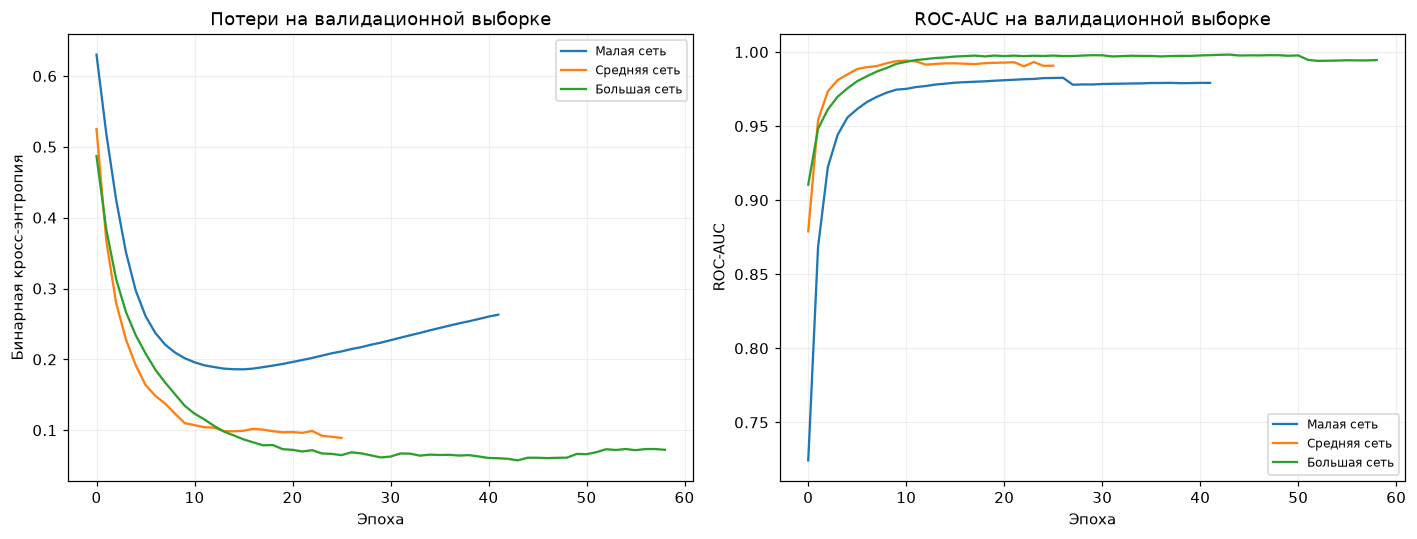

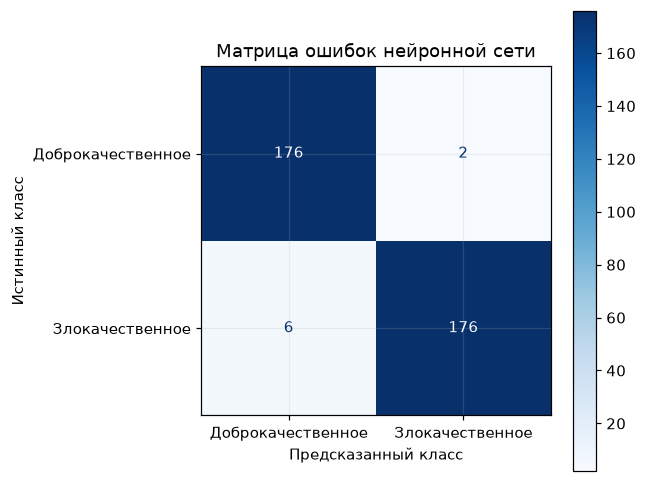

In [52]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,h in histories.items():
    axes[0].plot(h['val_loss'],label=name)
    axes[1].plot(h['val_auc'],label=name)
axes[0].set(title='Потери на валидационной выборке',xlabel='Эпоха',ylabel='Бинарная кросс-энтропия')
axes[1].set(title='ROC-AUC на валидационной выборке',xlabel='Эпоха',ylabel='ROC-AUC')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'nn_learning.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay.from_predictions(yte,q,display_labels=['Доброкачественное','Злокачественное'],cmap='Blues',ax=ax);ax.set(xlabel='Предсказанный класс',ylabel='Истинный класс',title='Матрица ошибок нейронной сети');fig.tight_layout();fig.savefig(OUT/'nn_confusion.png',dpi=180);plt.show()

**Анализ графиков обучения.** На левом графике снижение валидационных потерь означает улучшение вероятностных прогнозов; последующий рост потерь может указывать на переобучение. На правом графике более высокая ROC-AUC соответствует лучшему ранжированию классов. Сопоставление кривых разных архитектур позволяет оценить скорость сходимости и устойчивость. Матрица ошибок нейронной сети показывает число ложных тревог и пропущенных нечётных случаев.

### Просмотр TensorBoard

Запустите следующую ячейку в Jupyter (расширение должно поддерживать `%tensorboard`). Если отображение в VS Code не работает, откройте терминал в папке ноутбука и выполните:

```bash
tensorboard --logdir tensorboard_logs_lab2
```



In [ ]:

%load_ext tensorboard
%tensorboard --logdir tensorboard_logs_lab2

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

**Анализ TensorBoard.** Сравните кривые `epoch_loss`, `epoch_val_loss`, `epoch_auc` и `epoch_val_auc` между запусками. Разрыв между обучающими и валидационными кривыми указывает на возможное переобучение; ранняя остановка ограничивает дальнейшее ухудшение. TensorBoard сохраняет историю всех трёх экспериментов для воспроизводимого сравнения.

## 7. Итоговое сравнение и выводы

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Метод опорных векторов,0.9917,0.9945,0.9890,0.9917,0.9999
1,Метод ближайших соседей,0.9833,0.9731,0.9945,0.9837,0.9997
8,Нейронная сеть: Большая сеть,0.9778,0.9888,0.9670,0.9778,0.9986
2,Дерево решений,0.9222,0.9278,0.9176,0.9227,0.9741
3,Линейный дискриминантный анализ,0.8972,0.8919,0.9066,0.8992,0.9681
4,Бернуллиевский Байес,0.8472,0.8128,0.9066,0.8571,0.9402
5,Мультиномиальный Байес,0.8250,0.8083,0.8571,0.8320,0.9307
6,Комплементарный Байес,0.8250,0.8115,0.8516,0.8311,0.9307
7,Гауссовский Байес,0.6889,0.6215,0.9835,0.7617,0.9128


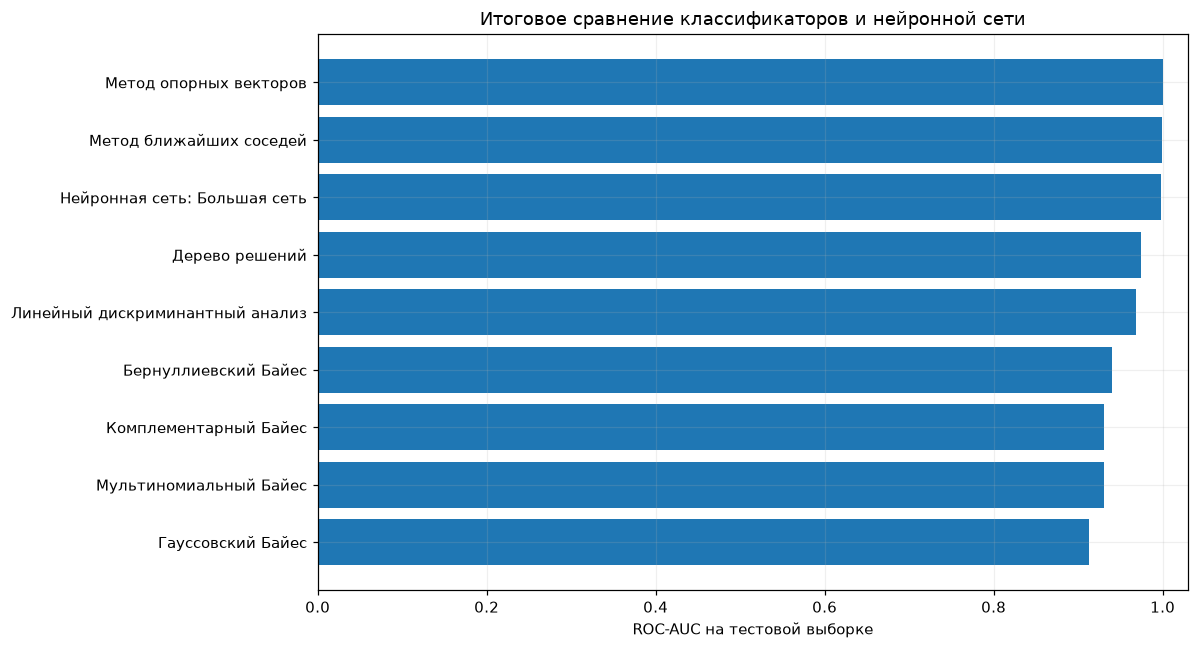

Лучшая классическая модель по кросс-валидации: Метод опорных векторов
Выбранная нейросеть по валидации: Большая сеть


In [54]:
all_metrics=pd.concat([metrics[['Модель','Accuracy','Precision','Recall','F1','ROC-AUC']],final_nn],ignore_index=True)
display(all_metrics.sort_values('ROC-AUC',ascending=False).round(4))
all_metrics.to_csv(OUT/'final_comparison.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(11,6));tmp=all_metrics.sort_values('ROC-AUC');ax.barh(tmp['Модель'],tmp['ROC-AUC']);ax.set(xlabel='ROC-AUC на тестовой выборке',title='Итоговое сравнение классификаторов и нейронной сети',xlim=(0,1.03));fig.tight_layout();fig.savefig(OUT/'final_comparison.png',dpi=180,bbox_inches='tight');plt.show()
print('Лучшая классическая модель по кросс-валидации:',best_name)
print('Выбранная нейросеть по валидации:',selected)

**Итоговая интерпретация.** Итоговая диаграмма позволяет сравнить классические классификаторы и нейронную сеть на одном и том же тестовом наборе. Высокий ROC-AUC означает хорошее разделение классов, но для практической оценки также важны Recall и число ложноотрицательных ответов. Выбор гиперпараметров выполнен по кросс-валидации или валидационной выборке; тест не используется для подбора. Победителя и конкретные числовые значения следует указать по полученной таблице после выполнения ноутбука. На небольшом наборе изображений сложная нейросеть не обязана превосходить SVM или другие классические методы.

## 8. Заключение

В работе реализованы четыре разновидности наивного байесовского классификатора, дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей. Для всех моделей выполнен подбор гиперпараметров и оценка Accuracy, Precision, Recall, F1 и ROC-AUC. Изучено влияние отдельных гиперпараметров на качество. Построена и обучена нейронная сеть TensorFlow, исследованы три архитектуры и записаны журналы TensorBoard. Все ключевые графики снабжены русскими подписями и интерпретациями.

**Ограничение:** исследуется чётность цифр, а не полное распознавание всех десяти классов. Для десятиклассовой задачи потребовалась бы иная постановка метрик и выходного слоя нейросети.

## 9. Источники

1. UCI Machine Learning Repository. *Optical Recognition of Handwritten Digits*: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
2. Scikit-learn. *Digits dataset*: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
3. Scikit-learn. *GridSearchCV*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
4. TensorFlow. *Keras*: https://www.tensorflow.org/guide/keras
5. TensorBoard. *Get started*: https://www.tensorflow.org/tensorboard/get_started

